# Importing Data

In [ ]:
import pandas as pd
from datasets import load_dataset
import numpy as np
from PIL import Image
import io
import re
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration for optional generated images
GENERATED_OUTPUT_DIR = None

ds = load_dataset("OmniGen2/OmniContext")
df = ds["train"].to_pandas()

def convert_image_list(image_data):
    if image_data is None:
        return []
    if isinstance(image_data, np.ndarray):
        image_records = image_data.tolist()
    elif isinstance(image_data, (list, tuple)):
        image_records = list(image_data)
    else:
        image_records = [image_data]

    images = []
    for record in image_records:
        if isinstance(record, Image.Image):
            images.append(record.convert("RGB"))
        elif isinstance(record, dict):
            image_bytes = record.get("bytes")
            image_path = record.get("path")
            if image_bytes is not None:
                image = Image.open(io.BytesIO(image_bytes)).convert("RGB")
                images.append(image)
            elif image_path:
                image = Image.open(image_path).convert("RGB")
                images.append(image)
    return images

df["context_images"] = df["input_images"].apply(convert_image_list)
df["num_input_images"] = df["context_images"].apply(len)

# Validation
assert len(df) == 400
assert df["key"].is_unique
assert df["num_input_images"].gt(0).all()

print(f"Processed {len(df)} rows. All validations passed.")
print(f"Total images decoded: {df['num_input_images'].sum()}")
print("Distribution of images per row:")
print(df['num_input_images'].value_counts())


Processed 400 rows. All validations passed.
Total images decoded: 790
Distribution of images per row:
num_input_images
2    210
1    100
3     90
Name: count, dtype: int64


The `input_images` column contains one or more reference context images for each task. All reference images are decoded into RGB PIL images and retained in the `context_images` column to preserve the multi-image context provided in the dataset.

Task type: single_character
Instruction: In the boiling basketball court, the man leaped into the air and completed a powerful one handed dunk.
Number of reference images: 1


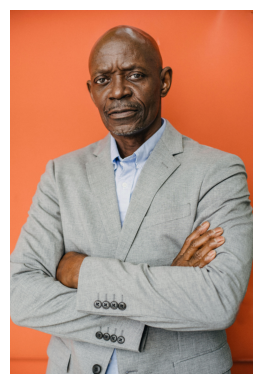

In [ ]:
sample_index = 19
sample = df.loc[sample_index]
images = sample["context_images"]

print("Task type:", sample["task_type"])
print("Instruction:", sample["instruction"])
print("Number of reference images:", len(images))

fig, axes = plt.subplots(1, len(images), figsize=(4 * len(images), 4))
axes = np.atleast_1d(axes)

for axis, image in zip(axes, images):
    axis.imshow(image)
    axis.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
print(f"Number of rows: {len(df)}")
print(f"Number of original columns: 5")
print("\nMissing values per original column:")
print(df[['task_type', 'instruction', 'input_images', 'instruction_language', 'key']].isnull().sum())

print(f"\nNumber of unique task types: {df['task_type'].nunique()}")
print("Observations per task type:")
print(df['task_type'].value_counts())

print("\nDistribution of reference images:")
print(df['num_input_images'].describe())


Number of rows: 400
Number of original columns: 5

Missing values per original column:
task_type               0
instruction             0
input_images            0
instruction_language    0
key                     0
dtype: int64

Number of unique task types: 8
Observations per task type:
task_type
single_character          50
single_object             50
multi_character           50
multi_object              50
multi_character_object    50
scene_character           50
scene_object              50
scene_character_object    50
Name: count, dtype: int64

Distribution of reference images:
count    400.000000
mean       1.975000
std        0.689611
min        1.000000
25%        1.750000
50%        2.000000
75%        2.000000
max        3.000000
Name: num_input_images, dtype: float64


In [ ]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:", df.columns.tolist())
print("\nData Types:\n", df.dtypes)
print("\nMissing Values:\n", df.isnull().sum())

Dataset Shape: (400, 7)

Column Names: ['task_type', 'instruction', 'input_images', 'instruction_language', 'key', 'context_images', 'num_input_images']

Data Types:
 task_type               object
instruction             object
input_images            object
instruction_language    object
key                     object
context_images          object
num_input_images         int64
dtype: object

Missing Values:
 task_type               0
instruction             0
input_images            0
instruction_language    0
key                     0
context_images          0
num_input_images        0
dtype: int64


In [ ]:
latex_description = r"""
\section*{Dataset Description}

Our dataset, `OmniContext`, consists of \textbf{400} samples and \textbf{5} original columns. Each sample represents a task involving natural language instructions and one or more reference context images.

\subsection*{Structure}
\begin{itemize}
    \item \textbf{task_type}: 8 balanced categories (50 rows each).
    \item \textbf{instruction}: Unique English prompts.
    \item \textbf{input_images}: Reference context images (not model-generated outputs).
    \item \textbf{context_images}: Decoded PIL images (derived).
    \item \textbf{num_input_images}: Count of reference images (derived).
\end{itemize}
"""
print(latex_description)


\section*{Dataset Description}

Our dataset, `OmniContext`, consists of \textbf{400} samples and \textbf{5} original columns. Each sample represents a task involving natural language instructions and one or more reference context images.

\subsection*{Structure}
\begin{itemize}
    \item \textbf{task_type}: 8 balanced categories (50 rows each).
    \item \textbf{instruction}: Unique English prompts.
    \item \textbf{input_images}: Reference context images (not model-generated outputs).
    \item \textbf{context_images}: Decoded PIL images (derived).
    \item \textbf{num_input_images}: Count of reference images (derived).
\end{itemize}



The dataset contains 400 observations with 5 original columns and 8 balanced task types. Each task includes one or more reference context images. Descriptive statistics for derived numerical variables, such as instruction length and alignment scores, will be calculated in subsequent sections.

# Data Cleaning and Exploratory Analysis

In [ ]:
import re
import numpy as np
# Removed: import pandas as pd (redundant)

# Ensure 'instruction' column is treated as string and features are re-calculated
df["instruction_char_count"] = df["instruction"].astype(str).str.len()
df["instruction_word_count"] = df["instruction"].astype(str).apply(lambda text: len(re.findall(r"\b\w+\b", text)))
df["instruction_sentence_count"] = df["instruction"].astype(str).apply(
    lambda text: max(1, len([part for part in re.split(r"[.!?]+", text) if part.strip()]))
)

def calculate_average_word_length(text):
    words = re.findall(r"\b\w+\b", str(text))
    return float(np.mean([len(word) for word in words])) if words else 0.0

df["average_word_length"] = df["instruction"].apply(calculate_average_word_length)

# Validation check cell
checks = {
    "400 rows": len(df) == 400,
    "unique keys": df["key"].is_unique,
    "eight task types": df["task_type"].nunique() == 8,
    "balanced task types": df["task_type"].value_counts().nunique() == 1,
    "all context images decoded": df["num_input_images"].gt(0).all(),
    "no task_type_numeric column": "task_type_numeric" not in df.columns
}

display(pd.Series(checks, name="passed").to_frame())
assert all(checks.values())

# Added print and assertion to verify instruction word counts are not all zero
print(f"Sum of instruction_word_count after calculation: {df['instruction_word_count'].sum()}")
assert df["instruction_word_count"].sum() > 0, "Error: instruction_word_count is still all zeros, check 'instruction' column data."
print("Instruction-based features calculated successfully with non-zero word counts.")

# Display descriptive statistics for new text features
text_feature_columns = ["instruction_char_count", "instruction_word_count", "instruction_sentence_count", "average_word_length", "num_input_images"]
display(df[text_feature_columns].describe().T.round(2))

,passed
400 rows,True
unique keys,True
eight task types,True
balanced task types,True
all context images decoded,True
no task_type_numeric column,True


Sum of instruction_word_count after calculation: 11798
Instruction-based features calculated successfully with non-zero word counts.


,count,mean,std,min,25%,50%,75%,max
instruction_char_count,400.0,167.71,122.95,25.00,91.00,134.50,203.25,726.00
instruction_word_count,400.0,29.50,19.97,4.00,17.00,25.00,36.25,119.00
instruction_sentence_count,400.0,1.22,0.71,1.00,1.00,1.00,1.00,5.00
average_word_length,400.0,4.51,0.48,2.86,4.17,4.54,4.89,5.76
num_input_images,400.0,1.98,0.69,1.00,1.75,2.00,2.00,3.00


Every task type appears exactly 50 times in this 400-sample dataset. All instructions are unique and written in English. Instruction length is measured in words, characters, and sentences, while the number of input images serves as a structural feature of the benchmark. Task type is categorical and will be one-hot encoded for modeling.

Do instruction word counts differ across OmniContext task categories?

# Text Analysis

# Linear Regression

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.model_selection import KFold, cross_validate

def build_linear_pipeline(numeric_features, categorical_features, quadratic=False):
    transformers = []
    if numeric_features:
        steps = [("scale", StandardScaler())]
        if quadratic: steps.append(("quadratic", PolynomialFeatures(degree=2, include_bias=False)))
        transformers.append(("numeric", Pipeline(steps), numeric_features))
    if categorical_features:
        transformers.append(("categorical", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), categorical_features))
    return Pipeline([("pre", ColumnTransformer(transformers, remainder="drop")), ("model", LinearRegression())])

def run_linear_analyses(df, target_col):
    scenarios = [
        ("Word Count", ["instruction_word_count"], []),
        ("Task Type", [], ["task_type"]),
        ("WC + Task", ["instruction_word_count"], ["task_type"]),
        ("WC + Task + Images", ["instruction_word_count", "num_input_images"], ["task_type"]),
        ("Quadratic WC + Task", ["instruction_word_count"], ["task_type"], True)
    ]
    results = []
    # Use KFold for continuous regression target
    cv = KFold(n_splits=5, shuffle=True, random_state=42)
    for name, num, cat, *quad in scenarios:
        is_quad = quad[0] if quad else False
        pipe = build_linear_pipeline(num, cat, quadratic=is_quad)
        cv_res = cross_validate(pipe, df, df[target_col], cv=cv, scoring=["r2", "neg_root_mean_squared_error"], return_train_score=True)
        results.append({"Model": name, "CV test R2 mean": cv_res["test_r2"].mean(), "CV test R2 std": cv_res["test_r2"].std(), "CV RMSE mean": -cv_res["test_neg_root_mean_squared_error"].mean(), "CV train R2 mean": cv_res["train_r2"].mean()})
    return pd.DataFrame(results), None

print("Linear-regression functions are defined. The models will run after the CLIP target is created.")

Linear-regression functions are defined. The models will run after the CLIP target is created.


In [ ]:
# This cell was empty or contained redundant plotting logic moved after CLIP calculation.

# Section removed (redundant)

In [ ]:
# Cell removed (redundant)

In [ ]:
print("Task categories used in one-hot encoding:")
for task_type in sorted(df["task_type"].unique()):
    print(task_type)

Task categories used in one-hot encoding:
multi_character
multi_character_object
multi_object
scene_character
scene_character_object
scene_object
single_character
single_object


## Calculating CLIP-Based Semantic Alignment

This section calculates CLIP-based cosine similarity between each instruction and all associated reference context images. Because the OmniContext dataset does not contain generated outputs, the default target measures instruction-context semantic alignment rather than model generation performance.

In [ ]:
import torch
from transformers import CLIPProcessor, CLIPModel
import torch.nn.functional as F

# Ensure packages are installed
%pip install -q transformers accelerate torch torchvision Pillow

In [ ]:
CLIP_MODEL_ID = "openai/clip-vit-base-patch32"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CLIPModel.from_pretrained(CLIP_MODEL_ID).to(device)
processor = CLIPProcessor.from_pretrained(CLIP_MODEL_ID)
model.eval()

CLIP_MAX_TOKENS = 77

df["clip_token_count"] = df["instruction"].apply(
    lambda text: len(processor.tokenizer(str(text), add_special_tokens=True, truncation=False)["input_ids"])
)
df["clip_text_truncated"] = df["clip_token_count"] > CLIP_MAX_TOKENS

print(f"Instructions exceeding {CLIP_MAX_TOKENS} tokens: {df['clip_text_truncated'].sum()}")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (111 > 77). Running this sequence through the model will result in indexing errors


Instructions exceeding 77 tokens: 28


In [ ]:
def calculate_clip_alignment(instruction, images):
    if not images:
        return []
    texts = [str(instruction)] * len(images)
    inputs = processor(text=texts, images=images, return_tensors="pt", padding=True, truncation=True, max_length=CLIP_MAX_TOKENS)
    inputs = {k: v.to(device) for k, v in inputs.items()}
    with torch.no_grad():
        outputs = model(**inputs)
    img_emb = F.normalize(outputs.image_embeds, p=2, dim=-1)
    txt_emb = F.normalize(outputs.text_embeds, p=2, dim=-1)
    return (img_emb * txt_emb).sum(dim=-1).cpu().numpy().tolist()

In [ ]:
df["context_alignment_similarities"] = df.apply(
    lambda row: calculate_clip_alignment(
        row["instruction"],
        row["context_images"]
    ),
    axis=1
)

df["context_alignment_score"] = (
    df["context_alignment_similarities"]
    .apply(
        lambda scores: (
            float(np.mean(scores))
            if len(scores) > 0
            else np.nan
        )
    )
)

assert df["context_alignment_score"].notna().all()

print("Context alignment scores calculated.")

# Display descriptive statistics for new alignment score
display(df[["context_alignment_score"]].describe())

Context alignment scores calculated.


,context_alignment_score
count,400.000000
mean,0.227223
std,0.038253
min,0.101265
25%,0.201492
50%,0.229343
75%,0.250496
max,0.358267


In [ ]:
# Removed duplicate CLIP calculation

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

,Model,CV test R2 mean,CV test R2 std,CV RMSE mean,CV train R2 mean
0,Word Count,-0.002672,0.029065,0.037928,0.023265
1,Task Type,0.358831,0.070084,0.030363,0.401790
2,WC + Task,0.355514,0.068764,0.030440,0.403363
3,WC + Task + Images,0.363450,0.072317,0.030245,0.413800
4,Quadratic WC + Task,0.349760,0.076621,0.030575,0.411331


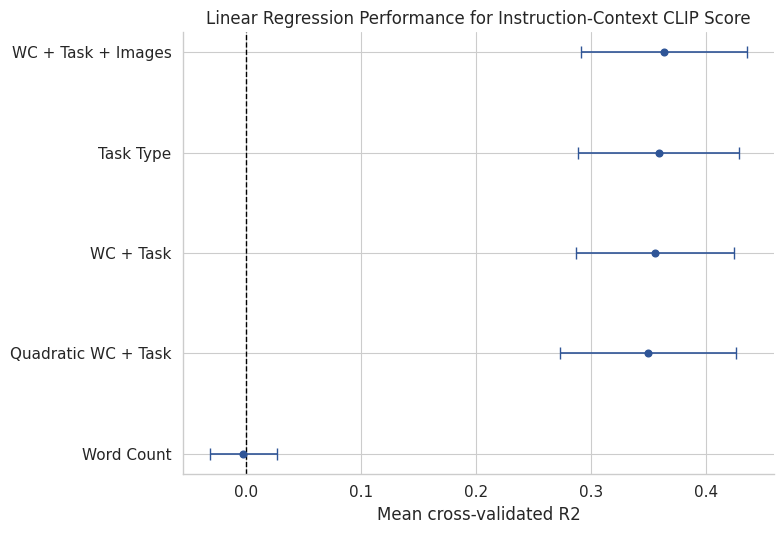

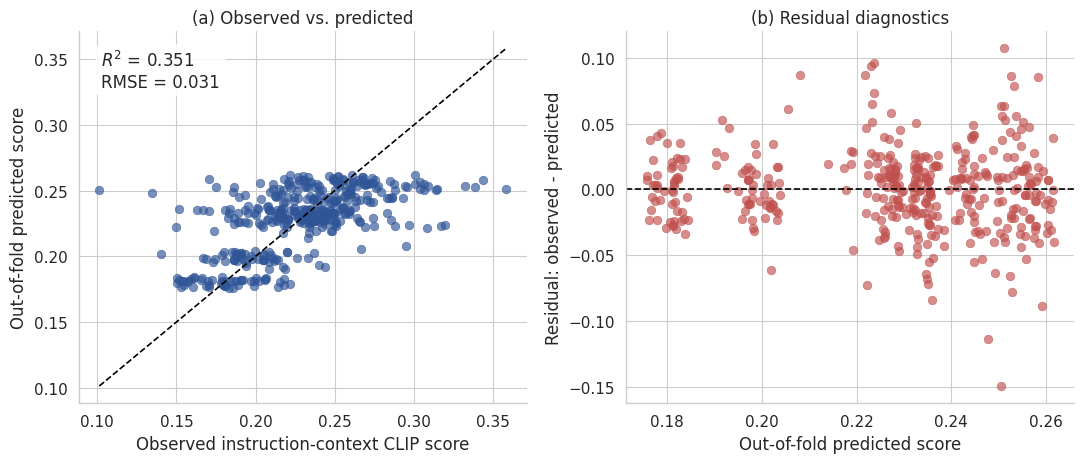

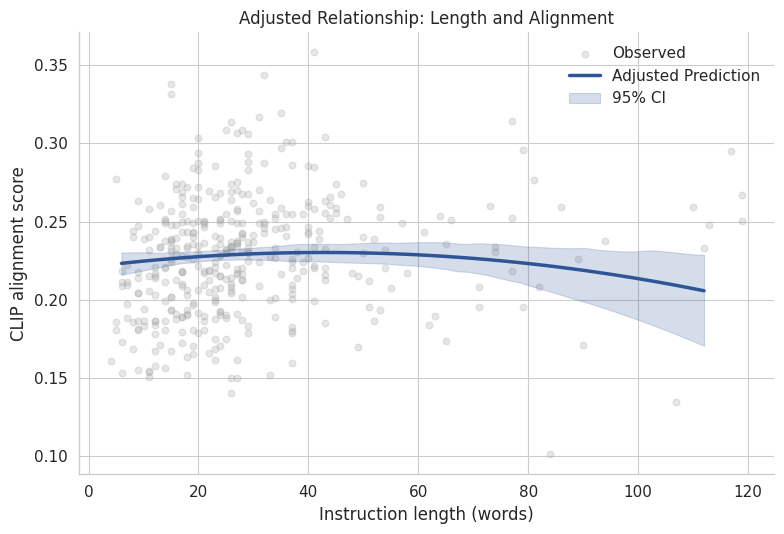

In [ ]:
import torch
from transformers import CLIPProcessor, CLIPModel
import torch.nn.functional as F
import numpy as np
from pathlib import Path
from sklearn.model_selection import cross_val_predict, KFold
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.base import clone

# Initialize CLIP for target calculation
CLIP_MODEL_ID = "openai/clip-vit-base-patch32"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
clip_model = CLIPModel.from_pretrained(CLIP_MODEL_ID).to(device)
clip_processor = CLIPProcessor.from_pretrained(CLIP_MODEL_ID)
clip_model.eval()
CLIP_MAX_TOKENS = 77

def calculate_clip_alignment(instruction, images):
    if not images:
        return []
    texts = [str(instruction)] * len(images)
    inputs = clip_processor(text=texts, images=images, return_tensors="pt", padding=True, truncation=True, max_length=CLIP_MAX_TOKENS)
    inputs = {k: v.to(device) for k, v in inputs.items()}
    with torch.no_grad():
        outputs = clip_model(**inputs)
    img_emb = F.normalize(outputs.image_embeds, p=2, dim=-1)
    txt_emb = F.normalize(outputs.text_embeds, p=2, dim=-1)
    return (img_emb * txt_emb).sum(dim=-1).cpu().numpy().tolist()

# Calculate semantic alignment score
df["context_alignment_similarities"] = df.apply(lambda row: calculate_clip_alignment(row["instruction"], row["context_images"]), axis=1)
df["context_alignment_score"] = df["context_alignment_similarities"].apply(lambda scores: float(np.mean(scores)) if len(scores) > 0 else np.nan)

# Run linear regression analyses
linear_results, _ = run_linear_analyses(df, target_col='context_alignment_score')
display(linear_results)

# --- Plotting Figures ---
sns.set_theme(context='paper', style='whitegrid', font_scale=1.25)
FIGURE_DIR = Path('paper_figures')
FIGURE_DIR.mkdir(exist_ok=True)

# Figure 1: Cross-validated performance comparison
plot_results = linear_results.copy().sort_values('CV test R2 mean', ascending=True)
fig1, ax1 = plt.subplots(figsize=(8, 5.5))
y_positions = np.arange(len(plot_results))
ax1.errorbar(plot_results['CV test R2 mean'], y_positions, xerr=plot_results['CV test R2 std'], fmt='o', color='#2F5597', capsize=4)
ax1.set_yticks(y_positions)
ax1.set_yticklabels(plot_results['Model'])
ax1.axvline(0, color='black', linestyle='--', linewidth=1)
ax1.set_xlabel('Mean cross-validated R2')
ax1.set_title('Linear Regression Performance for Instruction-Context CLIP Score')
sns.despine()
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'linear_model_comparison.png', dpi=300)
plt.show()

# Figure 2: Out-of-fold predictions and residuals
main_numeric_features = ["instruction_word_count"]
main_categorical_features = ["task_type"]
X_main = df[main_numeric_features + main_categorical_features].copy()
y_main = df["context_alignment_score"].copy()
main_model = build_linear_pipeline(numeric_features=main_numeric_features, categorical_features=main_categorical_features, quadratic=True)
cv = KFold(n_splits=5, shuffle=True, random_state=42)
oof_predictions = cross_val_predict(main_model, X_main, y_main, cv=cv, n_jobs=-1)
oof_r2 = r2_score(y_main, oof_predictions)
oof_rmse = np.sqrt(mean_squared_error(y_main, oof_predictions))
residuals = y_main - oof_predictions

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
sns.scatterplot(x=y_main, y=oof_predictions, color="#2F5597", alpha=0.65, s=38, edgecolor=None, ax=axes[0])
lower_limit, upper_limit = min(y_main.min(), oof_predictions.min()), max(y_main.max(), oof_predictions.max())
axes[0].plot([lower_limit, upper_limit], [lower_limit, upper_limit], linestyle="--", color="black", linewidth=1.2)
axes[0].set_xlabel("Observed instruction-context CLIP score")
axes[0].set_ylabel("Out-of-fold predicted score")
axes[0].set_title("(a) Observed vs. predicted")
axes[0].text(0.05, 0.95, f"$R^2$ = {oof_r2:.3f}\nRMSE = {oof_rmse:.3f}", transform=axes[0].transAxes, verticalalignment="top", bbox={"boxstyle": "round", "facecolor": "white", "alpha": 0.85})

sns.scatterplot(x=oof_predictions, y=residuals, color="#C0504D", alpha=0.65, s=38, edgecolor=None, ax=axes[1])
axes[1].axhline(0, color="black", linestyle="--", linewidth=1.2)
axes[1].set_xlabel("Out-of-fold predicted score")
axes[1].set_ylabel("Residual: observed - predicted")
axes[1].set_title("(b) Residual diagnostics")
sns.despine()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "linear_regression_oof_diagnostics.png", dpi=300)
plt.show()

# Figure 3: Adjusted instruction-length relationship
main_model.fit(X_main, y_main)
word_grid = np.linspace(df["instruction_word_count"].quantile(0.01), df["instruction_word_count"].quantile(0.99), 100)
prediction_frames = []
for word_count in word_grid:
    temporary_data = X_main.copy()
    temporary_data["instruction_word_count"] = word_count
    prediction_frames.append(temporary_data)
prediction_design = pd.concat(prediction_frames, ignore_index=True)
main_predictions = main_model.predict(prediction_design).reshape(len(word_grid), len(X_main))
adjusted_mean_prediction = main_predictions.mean(axis=1)

rng = np.random.default_rng(42)
bootstrap_curves = []
for _ in range(200):
    idx = rng.choice(np.arange(len(df)), size=len(df), replace=True)
    bm = clone(main_model)
    bm.fit(X_main.iloc[idx], y_main.iloc[idx])
    bp = bm.predict(prediction_design).reshape(len(word_grid), len(X_main))
    bootstrap_curves.append(bp.mean(axis=1))
bootstrap_curves = np.asarray(bootstrap_curves)
low, high = np.percentile(bootstrap_curves, [2.5, 97.5], axis=0)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(df["instruction_word_count"], df["context_alignment_score"], color="#A6A6A6", alpha=0.28, s=24, label="Observed")
ax.plot(word_grid, adjusted_mean_prediction, color="#2F5597", linewidth=2.5, label="Adjusted Prediction")
ax.fill_between(word_grid, low, high, color="#2F5597", alpha=0.20, label="95% CI")
ax.set_xlabel("Instruction length (words)")
ax.set_ylabel("CLIP alignment score")
ax.set_title("Adjusted Relationship: Length and Alignment")
ax.legend(frameon=False)
sns.despine()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "instruction_length_adjusted_relationship.png", dpi=300)
plt.show()

In [ ]:
# Verification block for missing values
cols_to_check = ["task_type", "instruction", "num_input_images", "instruction_word_count", "context_alignment_score"]
# Check for word count only if it was just created
if "instruction_word_count" in df.columns:
    cols_to_check.append("instruction_word_count")
print("Missing values check:")
print(df[cols_to_check].isnull().sum())

Missing values check:
task_type                  0
instruction                0
num_input_images           0
instruction_word_count     0
context_alignment_score    0
instruction_word_count     0
dtype: int64


In [ ]:
assert "run_linear_analyses" in globals()

linear_results, _ = run_linear_analyses(
    df,
    target_col="context_alignment_score"
)

assert isinstance(linear_results, pd.DataFrame)
assert not linear_results.empty

display(linear_results)

,Model,CV test R2 mean,CV test R2 std,CV RMSE mean,CV train R2 mean
0,Word Count,-0.002672,0.029065,0.037928,0.023265
1,Task Type,0.358831,0.070084,0.030363,0.401790
2,WC + Task,0.355514,0.068764,0.030440,0.403363
3,WC + Task + Images,0.363450,0.072317,0.030245,0.413800
4,Quadratic WC + Task,0.349760,0.076621,0.030575,0.411331


The CLIP-based `context_alignment_score` outcome has now been calculated. The linear-regression functions are defined, and the `linear_results` are produced in the subsequent cell, allowing the notebook to run from top to bottom without manually rerunning cells.

# Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, accuracy_score, balanced_accuracy_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Removed redundant feature recalculation, assuming K4X9Gq8XgU-E has run correctly.

# Assert context_alignment_score is present and valid
assert "context_alignment_score" in df.columns, "'context_alignment_score' column is missing. Ensure CLIP calculation cells are run."
assert df["context_alignment_score"].notna().all(), "'context_alignment_score' contains NaN values. Ensure CLIP calculation cells are run and valid."

train_index, test_index = train_test_split(df.index, test_size=0.2, random_state=42, stratify=df["task_type"])
threshold = df.loc[train_index, "context_alignment_score"].median() # Changed target

y_train = (df.loc[train_index, "context_alignment_score"] >= threshold).astype(int) # Changed target
y_test = (df.loc[test_index, "context_alignment_score"] >= threshold).astype(int) # Changed target

pre = ColumnTransformer([("num", StandardScaler(), ["instruction_word_count"]), ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), ["task_type"])])
log_pipe = Pipeline([("pre", pre), ("model", LogisticRegression())])

# Fit the pipeline before accessing its attributes
log_pipe.fit(df.loc[train_index, ["instruction_word_count", "task_type"]], y_train)

y_pred = log_pipe.predict(df.loc[test_index, ["instruction_word_count", "task_type"]])
y_prob = log_pipe.predict_proba(df.loc[test_index, ["instruction_word_count", "task_type"]])[:, 1]

dummy = DummyClassifier(strategy="most_frequent").fit(df.loc[train_index], y_train)

print(f"Baseline Accuracy: {accuracy_score(y_test, dummy.predict(df.loc[test_index])):.4f}")
print(f"Model Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_test, y_pred):.4f}")
print(f"ROC AUC: {roc_auc_score(y_test, y_prob):.4f}")

Baseline Accuracy: 0.4500
Model Accuracy: 0.7250
Balanced Accuracy: 0.7146
ROC AUC: 0.7629


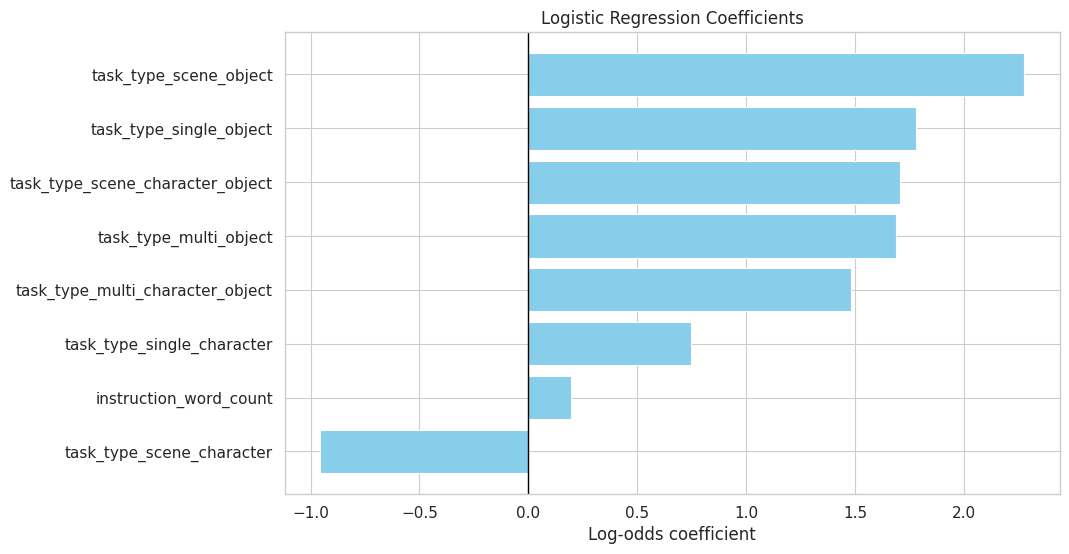

In [ ]:
import matplotlib.pyplot as plt

# Access coefficients from the fitted log_pipe
ohe = log_pipe.named_steps['pre'].named_transformers_['cat']
feat_names = ["instruction_word_count"] + list(ohe.get_feature_names_out(['task_type']))
coeffs = log_pipe.named_steps['model'].coef_[0]
importance_df = pd.DataFrame({"Feature": feat_names, "Coefficient": coeffs}).sort_values("Coefficient")

plt.figure(figsize=(10, 6))
plt.barh(importance_df["Feature"], importance_df["Coefficient"], color='skyblue')
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Log-odds coefficient")
plt.title("Logistic Regression Coefficients")
plt.show()

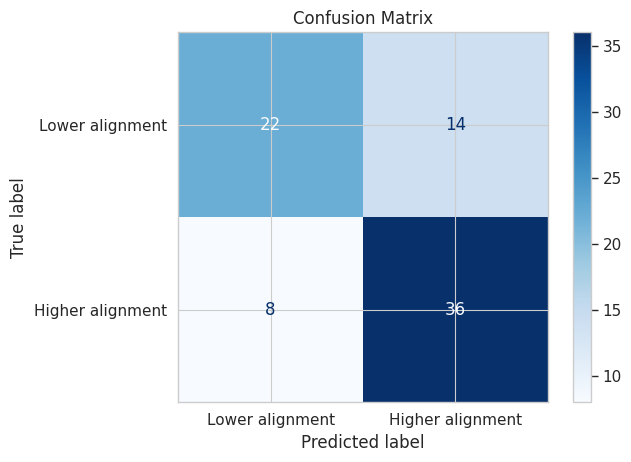

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Ensure features are present in the test slice
X_test = df.loc[test_index, ["instruction_word_count", "task_type"]]
ConfusionMatrixDisplay.from_estimator(log_pipe, X_test, y_test, display_labels=['Lower alignment', 'Higher alignment'], cmap='Blues')
plt.title("Confusion Matrix")
plt.show()

# Clustering Algo

## Clustering Analysis of Prompt and Context Features

This section uses K-Means to identify natural groupings in the data based on instruction structure and reference context. The CLIP outcome will be excluded from cluster formation to avoid leakage.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Removed: import re, numpy (redundant)

# Consolidate feature calculation for clustering to prevent KeyErrors
cluster_features = ["instruction_word_count", "instruction_sentence_count", "average_word_length", "num_input_images"]

# Removed redundant feature recalculation, assuming K4X9Gq8XgU-E has already run.

clustering_df = df[cluster_features].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(clustering_df)

print("Clustering features:", cluster_features)
print("Scaled data (first 5 rows):\n", X_scaled[:5])

Clustering features: ['instruction_word_count', 'instruction_sentence_count', 'average_word_length', 'num_input_images']
Scaled data (first 5 rows):
 [[ 2.63221823  3.94341842  1.60024026 -1.41561032]
 [ 0.2759806  -0.30442907  1.0206113  -1.41561032]
 [ 0.37624603 -0.30442907  1.63497714 -1.41561032]
 [ 0.17571517 -0.30442907  0.01867032 -1.41561032]
 [ 0.37624603 -0.30442907  0.29454258 -1.41561032]]


### Scaling the Data

### Determining Optimal Number of Clusters (Elbow Method)

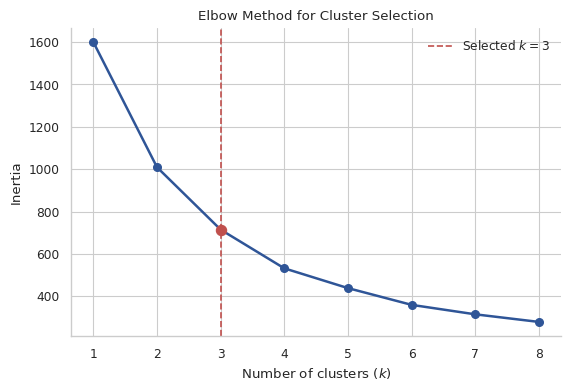

Selected number of clusters using the Elbow Method: 3


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Removed: import re (redundant)

# --------------------------------------------------
# Paper figure settings
# --------------------------------------------------
FIGURE_DIR = Path("paper_figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(context="paper", style="whitegrid", font_scale=1.0)

plt.rcParams.update({
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.facecolor": "white"
})

# Ensure df exists in the global namespace (already handled by top-level cells)
# Removed redundant df loading.

cluster_features = ["instruction_word_count", "instruction_sentence_count", "average_word_length", "num_input_images"]

# Removed redundant feature recalculation. Assumes K4X9Gq8XgU-E has run.
# if not all(col in df.columns for col in cluster_features):
#     ...

# --------------------------------------------------
# Prepare clustering features
# --------------------------------------------------
X_cluster = df[cluster_features].apply(pd.to_numeric, errors="coerce")
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

# --------------------------------------------------
# Elbow Method
# --------------------------------------------------
k_values = list(range(1, 9))
inertia_values = []

for k in k_values:
    kmeans_candidate = KMeans(n_clusters=k, random_state=42, n_init=20)
    kmeans_candidate.fit(X_scaled)
    inertia_values.append(kmeans_candidate.inertia_)

elbow_results = pd.DataFrame({"k": k_values, "inertia": inertia_values})
optimal_k = 3
selected_inertia = elbow_results.loc[elbow_results["k"].eq(optimal_k), "inertia"].iloc[0]

# --------------------------------------------------
# Publication-quality elbow figure
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(5.8, 4))
ax.plot(elbow_results["k"], elbow_results["inertia"], marker="o", markersize=5.5, linewidth=1.8, color="#2F5597")
ax.axvline(optimal_k, color="#C0504D", linestyle="--", linewidth=1.2, label=f"Selected $k={optimal_k}$")
ax.scatter([optimal_k], [selected_inertia], color="#C0504D", s=55, zorder=3)

ax.set_xlabel("Number of clusters ($k$)")
ax.set_ylabel("Inertia")
ax.set_title("Elbow Method for Cluster Selection")
ax.set_xticks(k_values)
ax.legend(frameon=False, loc="upper right")
sns.despine(ax=ax)
plt.tight_layout()
fig.savefig(FIGURE_DIR / "kmeans_elbow.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Selected number of clusters using the Elbow Method: {optimal_k}")


### Performing K-Means Clustering and PCA

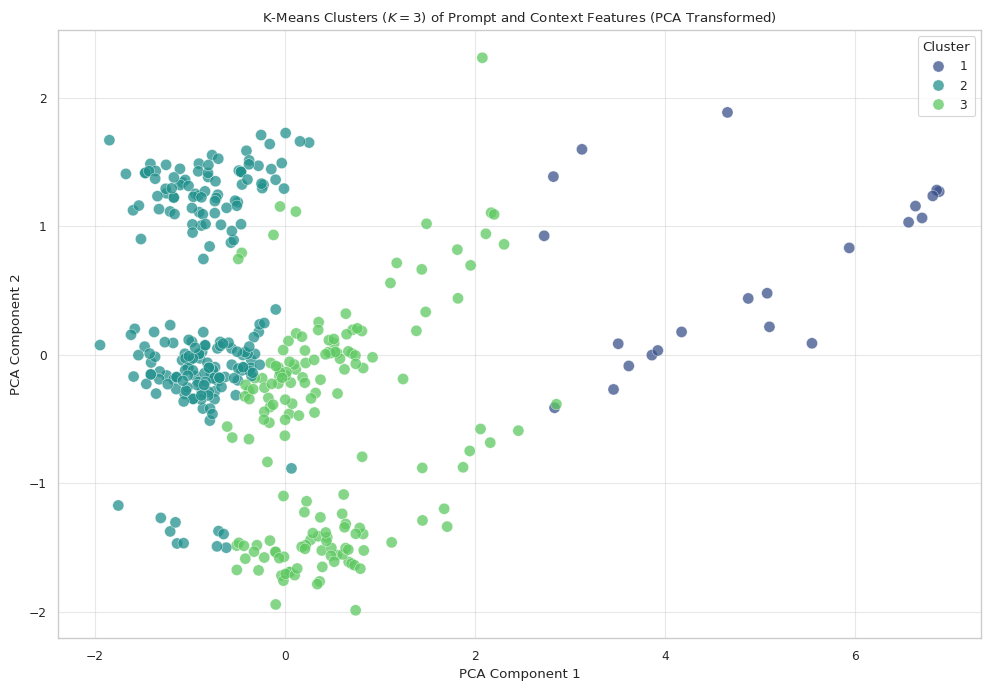

In [ ]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Ensure prerequisites are defined if this cell is run independently
# Removed redundant feature re-calculation, assuming K4X9Gq8XgU-E has run.
cluster_features = ["instruction_word_count", "instruction_sentence_count", "average_word_length", "num_input_images"]

# Ensure optimal_k is defined
if 'optimal_k' not in globals():
    optimal_k = 3 # Default if elbow method cell was not run

X_cluster = df[cluster_features].apply(pd.to_numeric, errors="coerce")
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

# --------------------------------------------------
# Fit the final K-means model
# --------------------------------------------------
km = KMeans(n_clusters=optimal_k, random_state=42, n_init=20)
clusters = km.fit_predict(X_scaled)

# Store cluster labels in dataframe
df["Cluster"] = clusters + 1

# --------------------------------------------------
# PCA Transformation
# --------------------------------------------------
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# --------------------------------------------------
# Create PCA visualization in the original style
# --------------------------------------------------

pca_plot_df = pd.DataFrame({
    "PCA Component 1": X_pca[:, 0],
    "PCA Component 2": X_pca[:, 1],
    "Cluster": (clusters + 1).astype(str)
})

cluster_order = [str(cluster_id + 1) for cluster_id in range(optimal_k)]

fig, ax = plt.subplots(figsize=(10, 7))

sns.scatterplot(
    data=pca_plot_df,
    x="PCA Component 1",
    y="PCA Component 2",
    hue="Cluster",
    hue_order=cluster_order,
    palette="viridis",
    s=65,
    alpha=0.75,
    edgecolor="white",
    linewidth=0.35,
    ax=ax
)

ax.set_title(
    f"K-Means Clusters ($K={optimal_k}$) of Prompt and "
    "Context Features (PCA Transformed)"
)

ax.set_xlabel("PCA Component 1")
ax.set_ylabel("PCA Component 2")

ax.legend(
    title="Cluster",
    loc="upper right",
    frameon=True
)

ax.grid(
    visible=True,
    alpha=0.45,
    linewidth=0.8
)

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "kmeans_pca_original_style.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    FIGURE_DIR / "kmeans_pca_original_style.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

### Interpreting Clustering Results

In [ ]:
# Ensure clustering_df and variables are correctly referenced
# Using df['Cluster'] which is ensured to be set in 7dfc5141
clustering_df = df[cluster_features].copy()
clustering_df["Cluster"] = df["Cluster"]
clustering_df["context_alignment_score"] = df.loc[clustering_df.index, "context_alignment_score"] # Changed target

cluster_summary = clustering_df.groupby("Cluster")[cluster_features + ["context_alignment_score"]].agg(["count", "mean", "std"]).round(3) # Changed target
display(cluster_summary)

print("\nThe clusters represent different prompt-length, sentence-structure, and reference-context profiles.")

instruction_word_count                 instruction_sentence_count  \
                         count    mean     std                      count   
Cluster                                                                     
1                           22  88.409  20.558                         22   
2                          212  21.896  10.121                        212   
3                          166  31.392  15.466                        166   

                      average_word_length               num_input_images  \
          mean    std               count   mean    std            count   
Cluster                                                                    
1        3.864  0.834                  22  4.921  0.319               22   
2        1.000  0.000                 212  4.190  0.382              212   
3        1.139  0.347                 166  4.855  0.306              166   

                      context_alignment_score                
          mean    std                   count   mean    std  
Cluster                                                      
1        1.182  0.395                      22  0.231  0.049  
2        2.344  0.575                     212  0.216  0.034  
3        1.608  0.559                     166  0.241  0.037


The clusters represent different prompt-length, sentence-structure, and reference-context profiles.


In [ ]:
# Removed duplicate clustering logic and generation_clip_score references.

# Final Validation

In [ ]:
required_columns = [
    "instruction_word_count",
    "instruction_sentence_count",
    "average_word_length",
    "num_input_images",
    "context_alignment_score",
    "Cluster"
]

missing_columns = [
    column
    for column in required_columns
    if column not in df.columns
]

assert not missing_columns, (
    f"Missing columns: {missing_columns}"
)

assert df[required_columns].notna().all().all()
assert df["instruction_word_count"].gt(0).all()
assert set(df["Cluster"].unique()) == {1, 2, 3}
assert len(linear_results) == 5

print(
    f"Validation successful: "
    f"{len(df)} samples, "
    f"{df['Cluster'].nunique()} clusters, "
    f"{len(linear_results)} regression models."
)

Validation successful: 400 samples, 3 clusters, 5 regression models.
